<a href="https://colab.research.google.com/github/careen-tech/COU07506_labs/blob/main/cou07506_week01_240242409.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

print("DSP Laboratory Setup Successful!")


DSP Laboratory Setup Successful!



# DIGITAL SIGNAL PROCESSING LABORATORY

**Module Code:** COU 07506

**Week:** 1

**Lab Title:** Setting Up the DSP Laboratory

**Student Name:** Careen Reginald Qamo

**Registration Number:** 240242409662

**Date:** Week 1 Lab 0
**Group:** Group 2

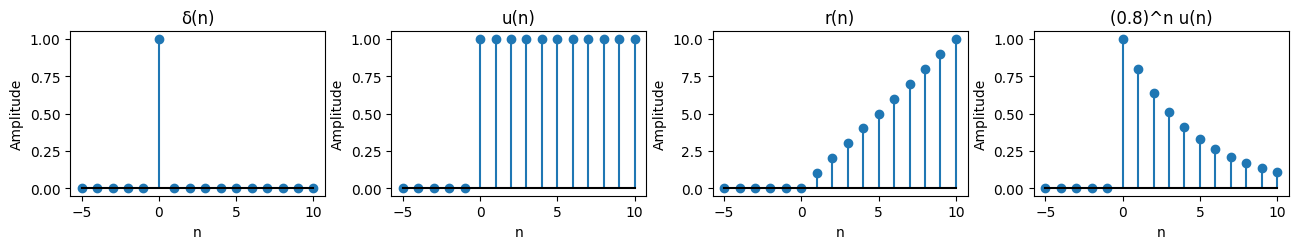

In [2]:

# Task 1.1: Elementary Discrete-Time Signals

import numpy as np
import matplotlib.pyplot as plt

# Define the discrete-time index
n = np.arange(-5, 11)

# Generate four signals
delta = (n == 0).astype(float)  # Unit impulse
step = (n >= 0).astype(float)   # Unit step
ramp = n * step                 # Unit ramp
expo = 0.8**n * step            # Exponential

# Create four subplots
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))

for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]
):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")

plt.tight_layout()
plt.show()


### Task 1.1 — Observation

Four elementary discrete-time signals were generated using NumPy and plotted using Matplotlib.

The unit impulse signal had a value of one at n = 0 and zero elsewhere. The unit step signal changed from zero to one at n = 0. The unit ramp signal increased linearly for non-negative values of n, while the exponential signal gradually decreased towards zero.

The results demonstrate the different characteristics of discrete-time signals used in digital signal processing.

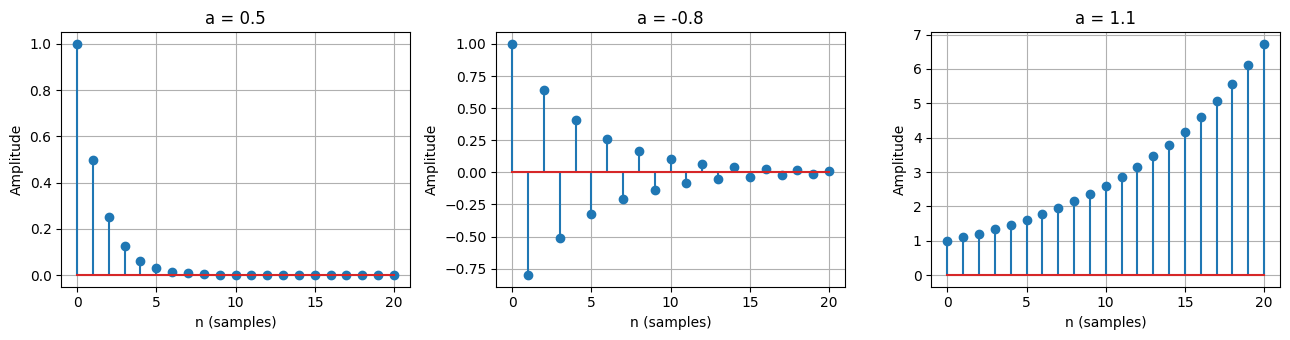

In [3]:

# Task 1.2 (a): Exponential Signals

import numpy as np
import matplotlib.pyplot as plt

n = np.arange(0, 21)

a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

for ax, a in zip(axes, a_values):
    x = a**n

    ax.stem(n, x)
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n (samples)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()


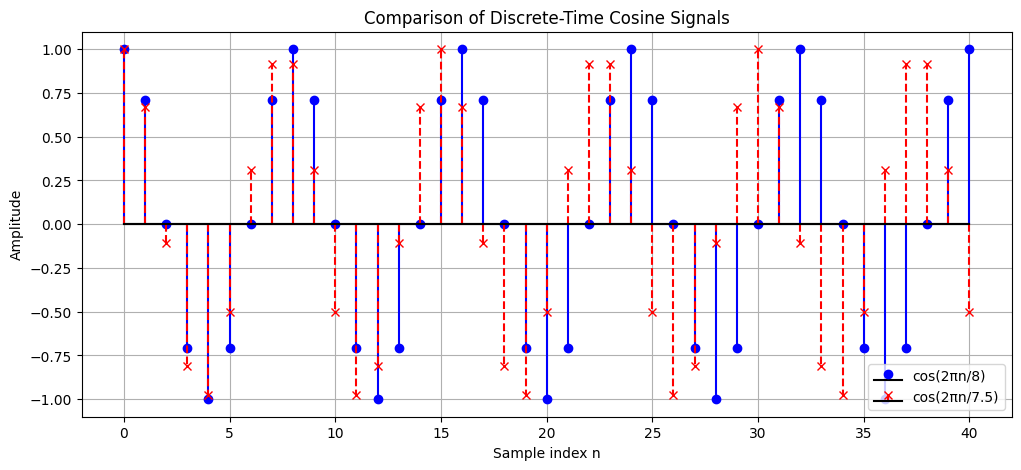

In [4]:

# Task 1.2 (b): Periodicity of Cosine Signals

import numpy as np
import matplotlib.pyplot as plt

n = np.arange(0, 41)

x1 = np.cos(2 * np.pi * n / 8)
x2 = np.cos(2 * np.pi * n / 7.5)

plt.figure(figsize=(12, 5))

plt.stem(n, x1, linefmt="b-", markerfmt="bo",
         basefmt="k-", label="cos(2πn/8)")

plt.stem(n, x2, linefmt="r--", markerfmt="rx",
         basefmt="k-", label="cos(2πn/7.5)")

plt.title("Comparison of Discrete-Time Cosine Signals")
plt.xlabel("Sample index n")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()


### Task 1.2 — Observations and Discussion

**Part (a): Exponential Signals**

Three exponential signals were generated using different values of a.

When a = 0.5, the signal decreased towards zero. When a = −0.8, the signal alternated between positive and negative values while decreasing in magnitude. When a = 1.1, the signal increased exponentially.

This demonstrates that the behaviour of an exponential signal depends on the magnitude and sign of its base.

**Part (b): Periodicity of Cosine Signals**

Two discrete-time cosine signals were generated and plotted for sample indices from 0 to 40.

The first signal repeated after every 8 samples, while the second repeated after every 15 samples.

Both signals are periodic because their angular frequencies are rational multiples of 2π.

Sampling rate = 44100 Hz
Duration = 6.89 seconds
Number of samples = 303879


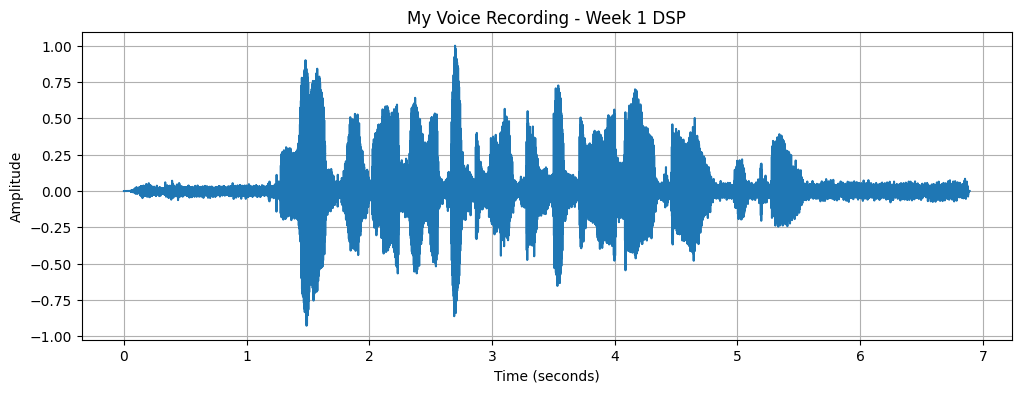

In [6]:

# Task 1.3: Working with Audio

import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

fname = "my_voice.wav"

if os.path.exists(fname):

    fs, x = wavfile.read(fname)

    # Convert stereo audio to mono
    if x.ndim > 1:
        x = x.mean(axis=1)

    # Convert to floating point
    x = x.astype(float)

    # Normalise the audio signal
    peak = np.max(np.abs(x))
    if peak > 0:
        x = x / peak

else:
    # Fallback test signal
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5 * np.sin(2*np.pi*440*t) * np.exp(-t)

# Generate time values
t = np.arange(len(x)) / fs

# Display audio information
print(f"Sampling rate = {fs} Hz")
print(f"Duration = {len(x)/fs:.2f} seconds")
print(f"Number of samples = {len(x)}")

# Plot waveform
plt.figure(figsize=(12, 4))
plt.plot(t, x)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("My Voice Recording - Week 1 DSP")
plt.grid(True)
plt.show()


In [7]:

from IPython.display import Audio, display

display(Audio(x, rate=fs))


In [8]:

print("Sampling frequency:", fs, "Hz")
print("Duration:", round(len(x) / fs, 2), "seconds")
print("Total samples:", len(x))


Sampling frequency: 44100 Hz
Duration: 6.89 seconds
Total samples: 303879


In [5]:
import os

print(os.path.exists("my_voice.wav"))

True
